# 1. Load the Dataset

In [13]:
import matplotlib.pyplot as plt 
import tensorflow as tf
import numpy as np 

mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [14]:
x_train.shape

(60000, 28, 28)

# 2. Preprocessing and normalizing the data

In [15]:
rows, cols = 28, 28 
x_train = x_train.reshape(x_train.shape[0], rows, cols, 1)
x_test = x_test.reshape(x_test.shape[0], rows, cols, 1) 
input_shape=(rows, cols, 1)

x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train = x_train/255.0 
x_test = x_test/255.0 

y_train=tf.keras.utils.to_categorical(y_train, 10)

In [16]:
x_train

array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
 

In [17]:
x_train.shape

(60000, 28, 28, 1)

In [18]:
y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(60000, 10))

In [19]:
y_train.shape

(60000, 10)

In [24]:
def build_lenet(input_shape):
    # Define Sequential Model 
    model = tf.keras.Sequential()
    # C1 Convolution Layer 
    model.add(tf.keras.layers.Conv2D(filters=6, strides=(1,1), kernel_size=(5,5), activation='tanh', input_shape=input_shape))
    
    # S2 Subsampling layer 
    model.add(tf.keras.layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)))
    
    # C3 Convolution Layer 
    model.add(tf.keras.layers.Conv2D(filters=6, strides=(1,1), kernel_size=(5,5), activation='tanh'))
    
    # S4 Subsampling Layer 
    model.add(tf.keras.layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)))
    
    # C5 Fully Connected Layer 
    model.add(tf.keras.layers.Dense(units=120, activation='tanh'))
    
    # Flatten the output so that we can connect it with the fully connected layers by converting it into a 1D Array 
    model.add(tf.keras.layers.Flatten())
    
    # FC6 Fully Conntect Layers 
    model.add(tf.keras.layers.Dense(units=84, activation='tanh'))
    
    # Output layer 
    model.add(tf.keras.layers.Dense(units=10, activation='softmax'))
    
    return model 

In [27]:
lenet = build_lenet(input_shape)

lenet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

epochs = 20 
history = lenet.fit(x_train, y_train, epochs=eposhs, batch_size=128, verbose=1)
# Check Accuracy of the Model
# Transform labels to one hot encoding
if len(y_test.shape) != 2 or y_test.shape[1] != 10:
  y_test = tf.keras.utils.to_categorical(y_test, 10)

loss ,acc= lenet.evaluate(x_test, y_test)
print('Accuracy : ', acc)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9031 - loss: 0.3381
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9572 - loss: 0.1450
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9694 - loss: 0.1039
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9754 - loss: 0.0839
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9799 - loss: 0.0688
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9819 - loss: 0.0593
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9844 - loss: 0.0511
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9862 - loss: 0.0451
Epoch 9/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9875 - loss: 0.0415
Epoch 10/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9886 - loss: 0.0369
Epoch 11/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9898 - loss: 0.0331
Epoch 12/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step

Training Data (60000, 28, 28) (60000, 10)
Test Data (10000, 28, 28) (10000, 10)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
9


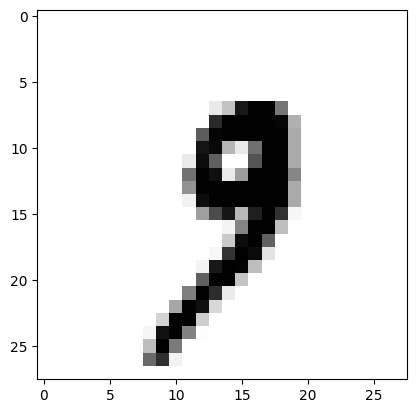

In [29]:
x_train = x_train.reshape(x_train.shape[0], 28,28)
print('Training Data', x_train.shape, y_train.shape)
x_test = x_test.reshape(x_test.shape[0], 28,28)
print('Test Data', x_test.shape, y_test.shape)

# Plot the Image
image_index = 1000
plt.imshow(x_test[image_index].reshape(28,28), cmap='Greys')

# Make Prediction
pred = lenet.predict(x_test[image_index].reshape(1, rows, cols, 1 ))
print(pred.argmax())